# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

The code and reflection cells are completed below. Interactive Plotly figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If Plotly figures do not render, set pio.renderers.default to "colab" in Colab
# or "notebook" in classic Jupyter.

data_path = Path("unit3_ppt7_card_transactions.csv")
if not data_path.exists():
    parent_candidate = Path.cwd().parent / "unit3_ppt7_card_transactions.csv"
    if parent_candidate.exists():
        data_path = parent_candidate
if not data_path.exists():
    raise FileNotFoundError(
        "Put unit3_ppt7_card_transactions.csv in the notebook's working directory and rerun."
    )

tx = pd.read_csv(data_path, parse_dates=["timestamp"])
required_columns = {
    "txn_id", "timestamp", "day", "hour", "customer_id", "city",
    "merchant_category", "amount_inr", "distance_from_home_km",
    "detector_score", "is_fraud"
}
missing_columns = required_columns.difference(tx.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if tx[list(required_columns)].isna().any().any():
    raise ValueError("The transaction dataset has missing values in required columns.")

tx["night"] = tx["hour"] < 6
tx["label"] = np.where(tx["is_fraud"] == 1, "confirmed fraud", "legitimate")

print(
    f"{len(tx):,} transactions | {int(tx.is_fraud.sum())} confirmed fraud "
    f"({tx.is_fraud.mean():.2%}) | days {tx.day.min()}-{tx.day.max()}"
)
tx.head()

5,520 transactions | 120 confirmed fraud (2.17%) | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**Steps:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

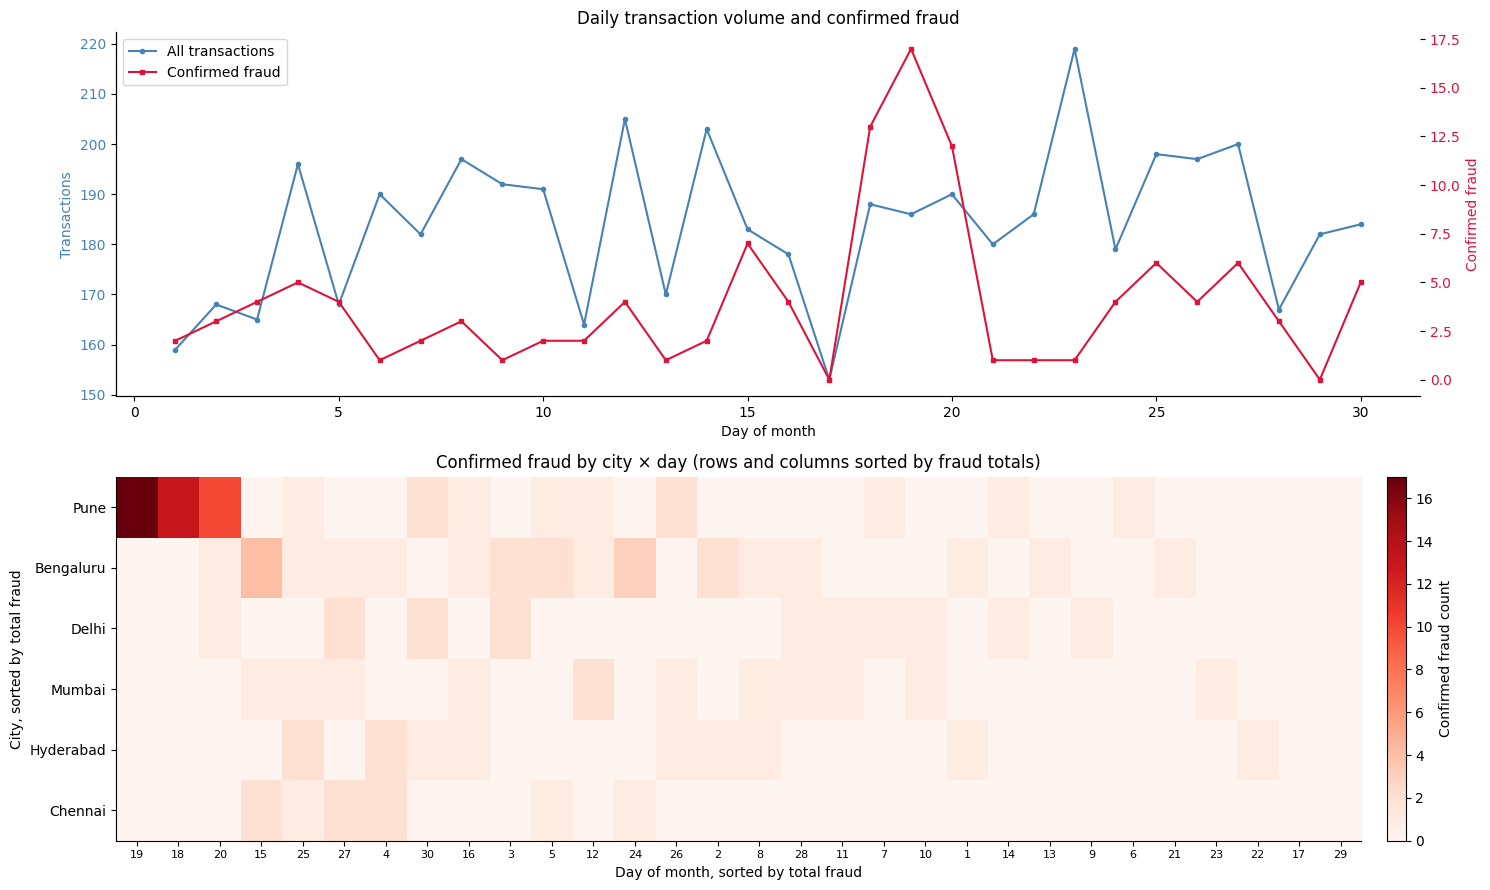

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           5       2
           2       2
           3       2
Chennai    27      2
Delhi      27      2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# 1. Daily volume and confirmed fraud on separate y-axes.
daily = (
    tx.groupby("day")
      .agg(transactions=("txn_id", "size"), confirmed_fraud=("is_fraud", "sum"))
      .sort_index()
)
ax_count = axes[0]
line_count = ax_count.plot(
    daily.index, daily["transactions"], marker="o", markersize=3,
    color="steelblue", label="All transactions"
)
ax_count.set_title("Daily transaction volume and confirmed fraud")
ax_count.set_xlabel("Day of month")
ax_count.set_ylabel("Transactions", color="steelblue")
ax_count.tick_params(axis="y", labelcolor="steelblue")
ax_fraud = ax_count.twinx()
line_fraud = ax_fraud.plot(
    daily.index, daily["confirmed_fraud"], marker="s", markersize=3,
    color="crimson", label="Confirmed fraud"
)
ax_fraud.set_ylabel("Confirmed fraud", color="crimson")
ax_fraud.tick_params(axis="y", labelcolor="crimson")
ax_count.legend(line_count + line_fraud,
                [line.get_label() for line in line_count + line_fraud],
                loc="upper left")

# 2. Fraud-count matrix, with both axes reordered by their totals.
heat = tx.pivot_table(
    index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0
)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat = heat.loc[:, heat.sum(axis=0).sort_values(ascending=False).index]
ax_heat = axes[1]
image = ax_heat.imshow(heat.to_numpy(), aspect="auto", cmap="Reds", interpolation="nearest")
ax_heat.set_title("Confirmed fraud by city × day (rows and columns sorted by fraud totals)")
ax_heat.set_xlabel("Day of month, sorted by total fraud")
ax_heat.set_ylabel("City, sorted by total fraud")
ax_heat.set_xticks(np.arange(len(heat.columns)))
ax_heat.set_xticklabels([str(int(day)) for day in heat.columns], fontsize=8)
ax_heat.set_yticks(np.arange(len(heat.index)))
ax_heat.set_yticklabels(heat.index)
fig.colorbar(image, ax=ax_heat, label="Confirmed fraud count", fraction=0.025, pad=0.02)

plt.tight_layout()
plt.show()

# 3. Print the city-day cells with the highest confirmed-fraud counts.
fraud_cells = (
    tx.loc[tx["is_fraud"] == 1]
      .groupby(["city", "day"])
      .size()
      .sort_values(ascending=False)
      .rename("confirmed_fraud")
)
print("Top city-day cells by confirmed fraud:")
print(fraud_cells.head(10).to_string())

**Reflection:** The overview showed a sharp Pune cluster on days 18–20: 40 confirmed frauds in three days, including 17 on day 19. An alert list sorted by score would show individual cases but hide that time-and-city pattern; the reordered heatmap (Slide 39) makes it obvious.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**Steps:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

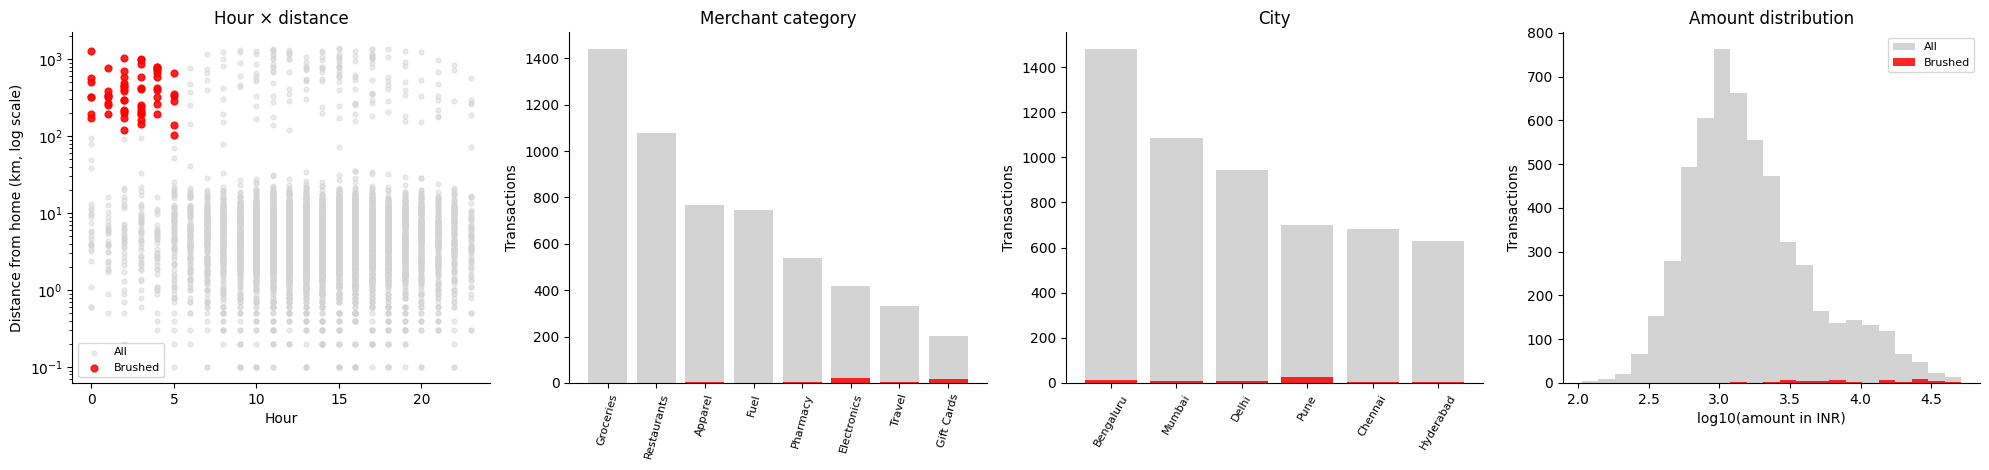

Brushed: 61 transactions; confirmed fraud: 53
Fraud rate: brush 86.9% vs. overall 2.17%
Share of all confirmed fraud captured by this rule: 44.2% (53/120)


In [3]:
# 1. Select night transactions more than 100 km from home.
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))

# (a) Hour versus distance. Clip zero only for display because a log axis cannot show zero.
plot_distance = tx["distance_from_home_km"].clip(lower=0.1)
axes[0].scatter(tx["hour"], plot_distance, s=12, color="lightgrey", alpha=0.45, label="All")
axes[0].scatter(tx.loc[brush, "hour"], plot_distance.loc[brush], s=24, color="red", alpha=0.85, label="Brushed")
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km, log scale)")
axes[0].set_title("Hour × distance")
axes[0].legend(fontsize=8)

# (b) Merchant-category counts, with the brushed subset overlaid in red.
category_order = tx["merchant_category"].value_counts().index
all_category = tx["merchant_category"].value_counts().reindex(category_order, fill_value=0)
brush_category = tx.loc[brush, "merchant_category"].value_counts().reindex(category_order, fill_value=0)
axes[1].bar(category_order, all_category, color="lightgrey", label="All")
axes[1].bar(category_order, brush_category, color="red", alpha=0.85, label="Brushed")
axes[1].set_title("Merchant category")
axes[1].set_ylabel("Transactions")
axes[1].tick_params(axis="x", rotation=75, labelsize=8)

# (c) City counts, same overlay.
city_order = tx["city"].value_counts().index
all_city = tx["city"].value_counts().reindex(city_order, fill_value=0)
brush_city = tx.loc[brush, "city"].value_counts().reindex(city_order, fill_value=0)
axes[2].bar(city_order, all_city, color="lightgrey", label="All")
axes[2].bar(city_order, brush_city, color="red", alpha=0.85, label="Brushed")
axes[2].set_title("City")
axes[2].set_ylabel("Transactions")
axes[2].tick_params(axis="x", rotation=60, labelsize=8)

# (d) Amount distribution on a log10-transformed x-axis.
log_amount = np.log10(tx["amount_inr"].clip(lower=1))
log_amount_brush = np.log10(tx.loc[brush, "amount_inr"].clip(lower=1))
bins = np.linspace(log_amount.min(), log_amount.max(), 24)
axes[3].hist(log_amount, bins=bins, color="lightgrey", label="All")
axes[3].hist(log_amount_brush, bins=bins, color="red", alpha=0.85, label="Brushed")
axes[3].set_title("Amount distribution")
axes[3].set_xlabel("log10(amount in INR)")
axes[3].set_ylabel("Transactions")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

# 3. Compare the brush with the whole dataset.
brush_count = int(brush.sum())
brush_fraud = int(tx.loc[brush, "is_fraud"].sum())
total_fraud = int(tx["is_fraud"].sum())
brush_rate = tx.loc[brush, "is_fraud"].mean() if brush_count else 0.0
overall_rate = tx["is_fraud"].mean()
fraud_capture = brush_fraud / total_fraud if total_fraud else 0.0
print(f"Brushed: {brush_count:,} transactions; confirmed fraud: {brush_fraud:,}")
print(f"Fraud rate: brush {brush_rate:.1%} vs. overall {overall_rate:.2%}")
print(f"Share of all confirmed fraud captured by this rule: {fraud_capture:.1%} ({brush_fraud}/{total_fraud})")

**Reflection:** The brush catches a high-risk slice, but it does not catch everything. Here it flags 61 transactions, 53 of which are fraud (86.9%), yet that is only 44.2% of all fraud. The merchant-category view hints at the rest: Electronics and Gift Cards also have fraud outside the night-and-far-from-home rule.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**Steps:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
# Build exactly 1,000,000 rows by repeating the supplied transaction data.
target_rows = 1_000_000
repeats = int(np.ceil(target_rows / len(tx)))
big = pd.concat([tx] * repeats, ignore_index=True).iloc[:target_rows]

# 1. Time the same boolean filter five times; use the fastest run as requested.
timings = []
for _ in range(5):
    started = time.perf_counter()
    mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    timings.append(time.perf_counter() - started)
best_s = min(timings)

# 2. Linear per-row cost and the approximate 0.1-second row budget.
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (per_item_us * 1e-6) if per_item_us > 0 else float("inf")

# 3. Rough linear projection to 50M rows and the fraction that must be skipped.
t_50m = 50_000_000 * per_item_us * 1e-6
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100) if t_50m > 0 else 0.0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.3f} s estimated; {skip_pct:.1f}% of rows need to be skipped to meet the 0.1 s budget.")
if t_50m <= 0.1:
    print("This simple filter fits the budget in this benchmark; rendering or returning 50M records can still be the bottleneck.")
print("This is a linear estimate from the fastest of five local runs, not a production latency guarantee.")

1,000,000 rows in 0.8 ms -> 0.0008 us/row -> max 132,930,112 rows in 0.1 s
50M rows -> 0.038 s estimated; 0.0% of rows need to be skipped to meet the 0.1 s budget.
This simple filter fits the budget in this benchmark; rendering or returning 50M records can still be the bottleneck.
This is a linear estimate from the fastest of five local runs, not a production latency guarantee.


**Reflection:** Pre-aggregate into time/amount bins or use a density view so the UI renders summaries, not millions of points. Even though this simple filter fits the 0.1 s budget here, showing 50M individual records is another problem; analysts also lose transaction-level detail and may miss rare outliers inside a bin.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**Steps:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

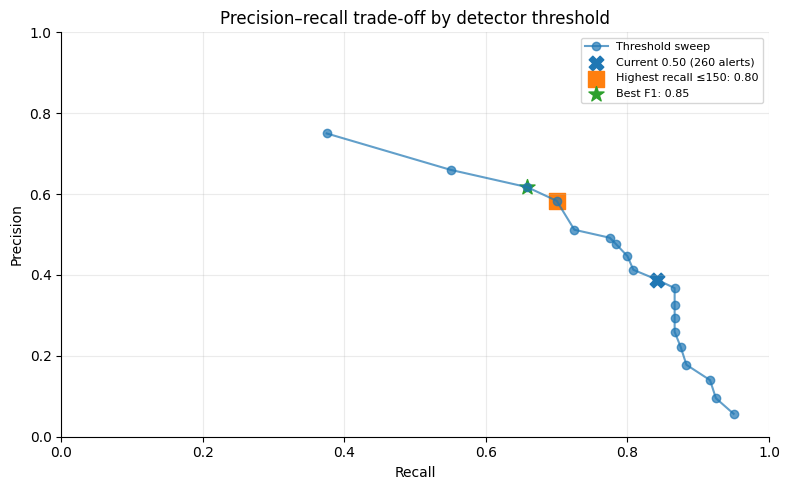

Recommend 0.85 for the best F1 (0.637): 128 alerts, precision 61.7%, recall 65.8%. The recall-maximizing choice under capacity is 0.80 (144 alerts, recall 70.0%).


In [5]:
# 1. Compute confusion-matrix counts and metrics for each threshold.
rows = []
actual = tx["is_fraud"].eq(1)
for threshold in np.round(np.arange(0.05, 0.951, 0.05), 2):
    predicted = tx["detector_score"] >= threshold
    alerts = int(predicted.sum())
    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    precision = tp / alerts if alerts else 0.0
    recall = tp / int(actual.sum()) if int(actual.sum()) else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
    rows.append({
        "threshold": float(threshold), "alerts": alerts, "tp": tp, "fp": fp,
        "fn": fn, "precision": precision, "recall": recall, "f1": f1
    })

pr = pd.DataFrame(rows)
pr.round({"threshold": 2, "precision": 3, "recall": 3, "f1": 3})

# 2. Capacity choice maximizes recall under 150 alerts; best_f1 maximizes F1 overall.
feasible = pr.loc[pr["alerts"] <= 150]
if feasible.empty:
    raise ValueError("No tested threshold meets the 150-alert capacity.")
capacity_choice = feasible.sort_values(
    ["recall", "precision", "threshold"], ascending=[False, False, False]
).iloc[0]
best_f1 = pr.loc[pr["f1"].idxmax()]
current_choice = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]

# 3. Precision-recall curve with all three operating points highlighted.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", linewidth=1.5, alpha=0.7,
        label="Threshold sweep")
ax.scatter(current_choice["recall"], current_choice["precision"], s=110, marker="X",
           label=f"Current 0.50 ({int(current_choice['alerts'])} alerts)")
ax.scatter(capacity_choice["recall"], capacity_choice["precision"], s=120, marker="s",
           label=f"Highest recall ≤150: {capacity_choice['threshold']:.2f}")
ax.scatter(best_f1["recall"], best_f1["precision"], s=130, marker="*",
           label=f"Best F1: {best_f1['threshold']:.2f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–recall trade-off by detector threshold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 4. Recommend the balanced best-F1 threshold while making the recall alternative clear.
print(
    f"Recommend {best_f1['threshold']:.2f} for the best F1 ({best_f1['f1']:.3f}): "
    f"{int(best_f1['alerts'])} alerts, precision {best_f1['precision']:.1%}, "
    f"recall {best_f1['recall']:.1%}. The recall-maximizing choice under capacity is "
    f"{capacity_choice['threshold']:.2f} ({int(capacity_choice['alerts'])} alerts, "
    f"recall {capacity_choice['recall']:.1%})."
)

**Reflection:** The Head of Fraud Ops should make the call, not the model. A threshold of 0.80 catches more fraud (70.0% recall) while 0.85 gives slightly better precision and F1, so it comes down to workload versus missed cases. Keeping a human in the loop makes that trade-off explicit instead of blindly optimizing one metric.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**Steps:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# 1. Interactive details-on-demand scatter for all detector scores >= 0.3.
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()
print(f"Interactive scatter includes {len(flagged):,} transactions with detector_score >= 0.3.")

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": ":.1f",
        "detector_score": ":.3f",
    },
    log_y=True,
    title="Flagged transactions (score ≥ 0.3): select cases and inspect details",
    labels={
        "timestamp": "Transaction time",
        "amount_inr": "Amount (INR, log scale)",
        "label": "Investigator label",
    },
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# 2. City → merchant-category sunburst, sized by transaction count and colored by fraud rate.
sunburst_data = (
    tx.groupby(["city", "merchant_category"], as_index=False)
      .agg(transactions=("txn_id", "size"), fraud_count=("is_fraud", "sum"))
)
sunburst_data["fraud_rate"] = sunburst_data["fraud_count"] / sunburst_data["transactions"]
fig_sunburst = px.sunburst(
    sunburst_data,
    path=["city", "merchant_category"],
    values="transactions",
    color="fraud_rate",
    color_continuous_scale="Reds",
    range_color=(0, 1),
    hover_data={
        "transactions": True,
        "fraud_count": True,
        "fraud_rate": ":.1%",
    },
    title="Transaction overview: city → merchant category (color = fraud rate)",
)
fig_sunburst.update_layout(coloraxis_colorbar={"title": "Fraud rate", "tickformat": ".0%"})
fig_sunburst.show()

Interactive scatter includes 401 transactions with detector_score >= 0.3.


**Reflection:** Hovering one transaction at a time is painful across 401 flagged cases and makes clusters hard to spot. The city × day heatmap from Task 1 gives the overview first; the sunburst then lets investigators drill into a city and category.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**Steps:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20 (the strongest three-day city window in the overview).
Window fraud rate: 37.38%; outside-window rate: 1.48%
Chi-square = 619.29, df = 1, p-value = 1.065e-136

Counter-example rates:
                   group  transactions  confirmed_fraud fraud_rate
        Pune, days 18–20           107               40     37.38%
        Pune, other days           593               11      1.85%
Other cities, days 18–20           457                2      0.44%
Other cities, other days          4363               67      1.54%


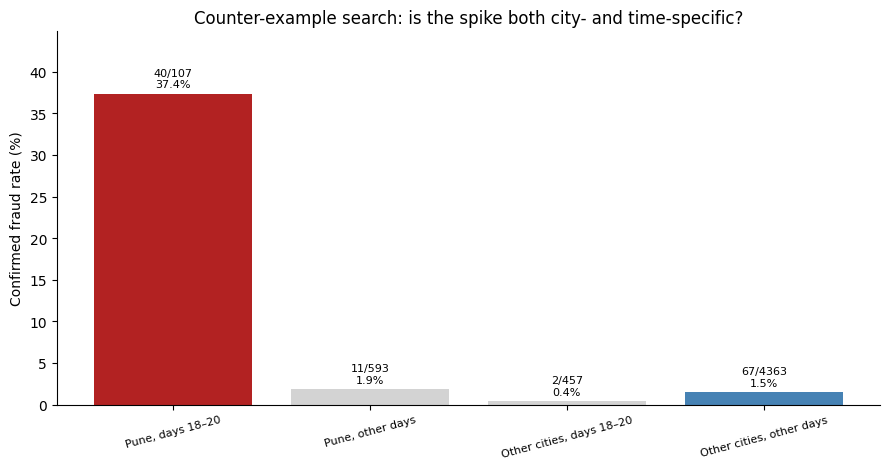

Verdict: strong evidence of a localized Pune fraud spike on days 18–20. Same-city other days are 1.85% and other cities on those days are 0.44%; this supports a city-and-time-specific anomaly, but shared customer/device/merchant links are still needed to call it a fraud ring.


In [7]:
from scipy.stats import chi2_contingency

# Identify the city and three-day window with the most confirmed fraud.
all_days = list(range(int(tx["day"].min()), int(tx["day"].max()) + 1))
fraud_by_city_day = (
    tx.loc[tx["is_fraud"] == 1]
      .groupby(["city", "day"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=all_days, fill_value=0)
)
window_candidates = []
for city_name, day_counts in fraud_by_city_day.iterrows():
    rolling_counts = day_counts.rolling(window=3).sum()
    end_day = int(rolling_counts.idxmax())
    window_candidates.append((int(rolling_counts.max()), city_name, end_day - 2, end_day))
window_fraud_count, hypothesis_city, start_day, end_day = max(
    window_candidates, key=lambda item: (item[0], item[1])
)
day_window = tx["day"].between(start_day, end_day)
in_window = tx["city"].eq(hypothesis_city) & day_window
same_city_other_days = tx["city"].eq(hypothesis_city) & ~day_window
other_cities_same_days = ~tx["city"].eq(hypothesis_city) & day_window
rest = ~(in_window | same_city_other_days | other_cities_same_days)

print(
    f"Hypothesis: confirmed fraud is unusually concentrated in {hypothesis_city} "
    f"on days {start_day}–{end_day} (the strongest three-day city window in the overview)."
)

# Compare the selected window with all transactions outside it, then run the requested chi-square test.
window_rate = tx.loc[in_window, "is_fraud"].mean() if in_window.any() else 0.0
outside_rate = tx.loc[~in_window, "is_fraud"].mean() if (~in_window).any() else 0.0
contingency = pd.crosstab(in_window, tx["is_fraud"]).reindex(
    index=[False, True], columns=[0, 1], fill_value=0
)
chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f"Window fraud rate: {window_rate:.2%}; outside-window rate: {outside_rate:.2%}")
print(f"Chi-square = {chi2:.2f}, df = {dof}, p-value = {p_value:.3e}")

# Counter-example searches and four mutually exclusive groups for the chart.
group_masks = {
    f"{hypothesis_city}, days {start_day}–{end_day}": in_window,
    f"{hypothesis_city}, other days": same_city_other_days,
    f"Other cities, days {start_day}–{end_day}": other_cities_same_days,
    "Other cities, other days": rest,
}
group_rows = []
for group_name, group_mask in group_masks.items():
    subset = tx.loc[group_mask, "is_fraud"]
    group_rows.append({
        "group": group_name,
        "transactions": int(group_mask.sum()),
        "confirmed_fraud": int(subset.sum()),
        "fraud_rate": float(subset.mean()) if len(subset) else 0.0,
    })
group_stats = pd.DataFrame(group_rows)
print("\nCounter-example rates:")
print(group_stats.to_string(index=False, formatters={"fraud_rate": lambda rate: f"{rate:.2%}"}))

# Visual confirmation: compare fraud rates across the four groups.
fig, ax = plt.subplots(figsize=(9, 4.8))
bar_labels = group_stats["group"].tolist()
bar_rates = group_stats["fraud_rate"].to_numpy() * 100
bars = ax.bar(bar_labels, bar_rates, color=["firebrick", "lightgrey", "lightgrey", "steelblue"])
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Counter-example search: is the spike both city- and time-specific?")
ax.tick_params(axis="x", rotation=15, labelsize=8)
for bar, row in zip(bars, group_stats.to_dict("records")):
    ax.annotate(
        f"{row['confirmed_fraud']}/{row['transactions']}\n{row['fraud_rate']:.1%}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8
    )
ax.margins(y=0.20)
plt.tight_layout()
plt.show()

# Verdict: the data can show a localized anomaly, but not prove a coordinated ring by itself.
same_city_rate = float(group_stats.loc[group_stats["group"] == f"{hypothesis_city}, other days", "fraud_rate"].iloc[0])
same_days_rate = float(group_stats.loc[group_stats["group"] == f"Other cities, days {start_day}–{end_day}", "fraud_rate"].iloc[0])
if p_value < 0.001 and window_rate > outside_rate:
    print(
        f"Verdict: strong evidence of a localized {hypothesis_city} fraud spike on days "
        f"{start_day}–{end_day}. Same-city other days are {same_city_rate:.2%} and other cities "
        f"on those days are {same_days_rate:.2%}; this supports a city-and-time-specific anomaly, "
        "but shared customer/device/merchant links are still needed to call it a fraud ring."
    )
else:
    print(
        "Verdict: this window is not statistically strong enough to support a localized-ring claim; "
        "investigate broader city/date patterns before escalating."
    )

**Reflection:** The strongest check is other cities on the same days: if they had similarly high fraud, this would look like a date-wide campaign rather than a Pune-specific cluster. Same-city fraud on other days is near the baseline, which supports the spike being time-limited. Even so, a cluster is not proof of a coordinated ring without shared customer, device or merchant links.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month’s detector is better.

_Your final note here:_

Last month, 120 of 5,520 transactions were confirmed fraud (2.17%), with 40 clustered in Pune on days 18–20 (37.4% of the 107 transactions in that window). I’d use threshold 0.85: it gives 128 alerts, within the 150-case limit, with 61.7% precision and 65.8% recall (F1 0.637), though the Head of Fraud Ops should own that trade-off; 0.80 is the recall-maximizing option under capacity. I’d build the city-to-category sunburst first because it gives an overview and lets investigators drill down. Feed confirmed investigator outcomes back into the labelled data, then retrain and evaluate next month’s detector.